# EV Battery Health Prediction: Step 2, Data Exploration (EDA)

In Step 1 I loaded a single battery (B0005). In this notebook I load **four batteries** into one table, check the data quality, and explore how voltage, temperature and discharge time change as the batteries age.

The goal of this step is to understand the data before modelling, and to decide which columns are worth using as model inputs.

| Step | What I do |
|---|---|
| 1 | Load the NASA data for one battery, calculate SOH, plot the capacity fade |
| **2 (this notebook)** | **Combine 4 batteries, check quality, explore patterns** |
| 3 | Train models to predict SOH |
| 4 | Explain the best model with SHAP |
| 5 | Predict Remaining Useful Life (RUL) |
| 6 | Build and deploy a Streamlit app |

## 1. Importing libraries

`seaborn` is added here for the correlation heatmap.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import loadmat

## 2. Loading all four batteries

I reuse the same logic as Step 1: keep only the discharge cycles and summarise each one into a single row. The difference is that I do it for four batteries and stack them into **one table** with a `battery` column, so I can compare them and later split them for training and testing.

In [2]:
BATTERIES = ["B0005", "B0006", "B0007", "B0018"]


def load_discharge_cycles(file_path, battery_name):
    """Read a NASA .mat file and return one row per discharge cycle."""
    mat = loadmat(file_path)
    cycles = mat[battery_name][0, 0]["cycle"][0]

    rows = []
    discharge_number = 0

    for cycle in cycles:
        if cycle["type"][0] != "discharge":
            continue

        discharge_number += 1
        d = cycle["data"][0, 0]

        voltage = d["Voltage_measured"][0]
        current = d["Current_measured"][0]
        temp = d["Temperature_measured"][0]
        time = d["Time"][0]
        capacity = d["Capacity"][0][0]

        rows.append(
            {
                "cycle": discharge_number,
                "capacity_ah": capacity,
                "avg_voltage": np.mean(voltage),
                "min_voltage": np.min(voltage),
                "avg_current": np.mean(current),
                "avg_temp": np.mean(temp),
                "max_temp": np.max(temp),
                "discharge_time_s": time[-1],
            }
        )

    return pd.DataFrame(rows)


def add_soh(df):
    """SOH (%) = current capacity / starting capacity x 100"""
    df["soh_percent"] = df["capacity_ah"] / df["capacity_ah"].iloc[0] * 100
    return df


frames = []
for name in BATTERIES:
    battery_df = load_discharge_cycles(f"data/{name}.mat", name)
    battery_df = add_soh(battery_df)
    battery_df["battery"] = name
    frames.append(battery_df)

df = pd.concat(frames, ignore_index=True)
df.head()

,cycle,capacity_ah,avg_voltage,min_voltage,avg_current,avg_temp,max_temp,discharge_time_s,soh_percent,battery
0,1,1.856487,3.529829,2.612467,-1.818702,32.572328,38.982181,3690.234,100.000000,B0005
1,2,1.846327,3.537320,2.587209,-1.817560,32.725235,39.033398,3672.344,99.452721,B0005
2,3,1.835349,3.543737,2.651917,-1.816487,32.642862,38.818797,3651.641,98.861386,B0005
3,4,1.835263,3.543666,2.592948,-1.825589,32.514876,38.762305,3631.563,98.856718,B0005
4,5,1.834646,3.542343,2.547420,-1.826114,32.382349,38.665393,3629.172,98.823482,B0005


## 3. Data quality checks

Before drawing any conclusions I checked the basics: size, number of cycles per battery, data types, missing values and duplicates. A model can quietly give wrong results if the input data has problems, so it is better to look first.

In [3]:
print("Shape:", df.shape)
print()
print("Discharge cycles per battery:")
print(df["battery"].value_counts())
print()
print("Data types:")
print(df.dtypes)

Shape: (636, 10)

Discharge cycles per battery:
battery
B0005    168
B0006    168
B0007    168
B0018    132
Name: count, dtype: int64

Data types:
cycle                 int64
capacity_ah         float64
avg_voltage         float64
min_voltage         float64
avg_current         float64
avg_temp            float64
max_temp            float64
discharge_time_s    float64
soh_percent         float64
battery                 str
dtype: object


In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
cycle               0
capacity_ah         0
avg_voltage         0
min_voltage         0
avg_current         0
avg_temp            0
max_temp            0
discharge_time_s    0
soh_percent         0
battery             0
dtype: int64

Duplicate rows: 0


In [5]:
df.describe().round(3)

,cycle,capacity_ah,avg_voltage,min_voltage,avg_current,avg_temp,max_temp,discharge_time_s,soh_percent
count,636.000,636.000,636.000,636.000,636.000,636.000,636.000,636.000,636.000
mean,80.764,1.582,3.499,2.388,-1.834,32.328,39.571,3116.978,82.848
std,47.137,0.199,0.048,0.220,0.103,0.971,1.439,242.197,10.931
min,1.000,1.154,3.404,1.737,-2.000,30.103,36.372,2742.843,56.689
25%,40.000,1.421,3.467,2.187,-1.913,31.517,38.371,2891.996,74.807
50%,80.000,1.560,3.503,2.421,-1.851,32.368,39.672,3084.281,82.318
75%,120.000,1.763,3.541,2.529,-1.773,33.175,40.870,3311.828,92.526
max,168.000,2.035,3.574,2.700,-1.517,34.490,42.333,3690.234,100.000


## 4. Saving the combined table

Step 3 reads this file to train the models.

In [6]:
df.to_csv("all_batteries.csv", index=False)
print("Saved all_batteries.csv with", len(df), "rows")

Saved all_batteries.csv with 636 rows


## 5. Do all four batteries age the same way?

I plotted the capacity of all four batteries on one graph. The red dashed line at **1.4 Ah** marks roughly a 30% fade from the starting capacity of about 2 Ah.

This matters because later I train on some batteries and test on another one. If the batteries age very differently, a model trained on a few of them may not transfer well to a new one.

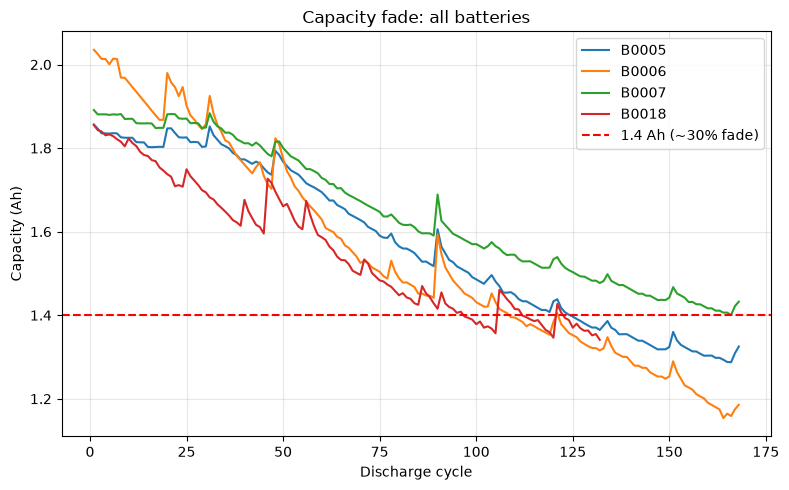

In [7]:
plt.figure(figsize=(8, 5))
for name, g in df.groupby("battery"):
    plt.plot(g["cycle"], g["capacity_ah"], label=name)

plt.axhline(1.4, color="red", linestyle="--", label="1.4 Ah (~30% fade)")
plt.title("Capacity fade: all batteries")
plt.xlabel("Discharge cycle")
plt.ylabel("Capacity (Ah)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("all_batteries_capacity.png", dpi=150)
plt.show()

## 6. How do the other measurements change with age?

Capacity can only be measured by running a full discharge, which is not practical in a real EV. What I would like is to estimate SOH from things that are easy to measure. So I checked how voltage, temperature and discharge time change over the life of one battery (B0005).

If a feature changes in a clear direction as the battery ages, it is likely to be useful for predicting SOH. If it stays flat or is just noise, it probably will not help much.

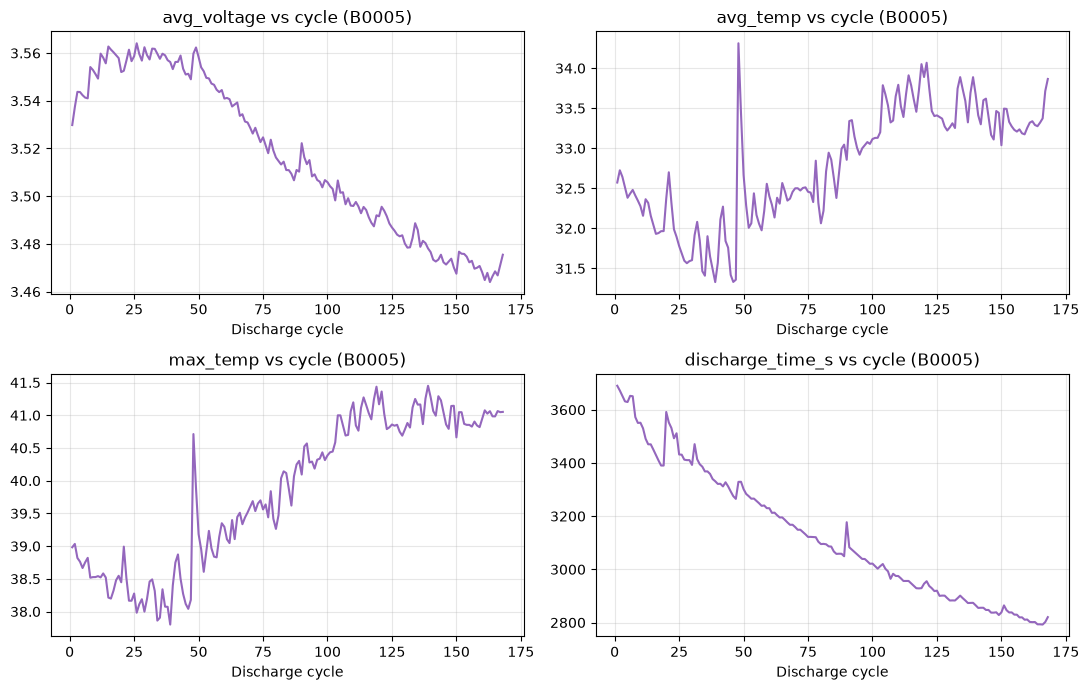

In [8]:
g = df[df["battery"] == "B0005"]
features = ["avg_voltage", "avg_temp", "max_temp", "discharge_time_s"]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, feat in zip(axes.ravel(), features):
    ax.plot(g["cycle"], g[feat], color="tab:purple")
    ax.set_title(f"{feat} vs cycle (B0005)")
    ax.set_xlabel("Discharge cycle")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("features_vs_cycle.png", dpi=150)
plt.show()

## 7. Correlation heatmap

A correlation heatmap shows how strongly each pair of columns moves together.

| Value | Meaning |
|---|---|
| Close to **+1** | They rise together |
| Close to **-1** | One rises while the other falls |
| Close to **0** | No clear linear relationship |

I mainly look at the `capacity_ah` and `soh_percent` rows to see which features move with battery health.

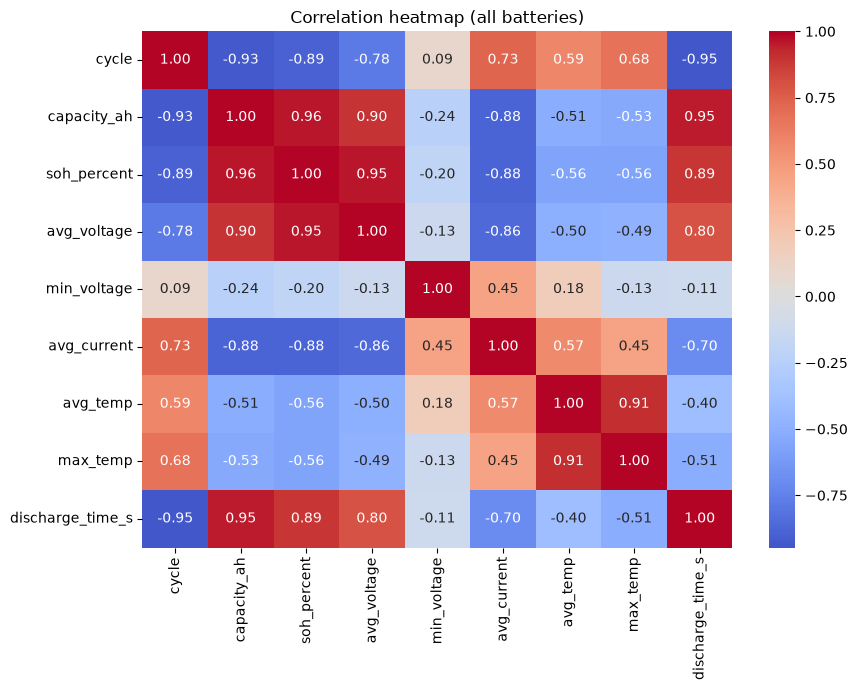

In [9]:
cols = [
    "cycle", "capacity_ah", "soh_percent", "avg_voltage", "min_voltage",
    "avg_current", "avg_temp", "max_temp", "discharge_time_s",
]
corr = df[cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap (all batteries)")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=150)
plt.show()

In [10]:
# Features ranked by strength of correlation with capacity
(
    corr["capacity_ah"]
    .drop("capacity_ah")
    .sort_values(key=abs, ascending=False)
    .round(3)
)

soh_percent         0.959
discharge_time_s    0.952
cycle              -0.929
avg_voltage         0.896
avg_current        -0.884
max_temp           -0.534
avg_temp           -0.510
min_voltage        -0.243
Name: capacity_ah, dtype: float64

## 8. A note on the `cycle` column

`cycle` will naturally correlate strongly with capacity, because capacity falls as cycles pile up. That is expected, but it is not a good model input for a real EV, since a vehicle does not always know exactly how many cycles its battery has been through.

So in Step 3 I train the models **without** `cycle` and compare the result with a version that includes it.

## 9. My observations from this run

- **Missing values / duplicates:** none. The table has 636 rows, 0 missing values and 0 duplicate rows.
- **Cycles per battery:** B0005, B0006 and B0007 have 168 discharge cycles each, and B0018 has 132.
- **Do all four batteries fade in a similar way?** The overall shape is the same: capacity falls steadily with small upward bumps (capacity regeneration). The amount differs. B0006 starts highest (about 2.04 Ah) and ends lowest (about 1.19 Ah, roughly 58% SOH), while B0007 fades the least (about 1.43 Ah at its last cycle). The four cells also start at different capacities (about 1.86 to 2.04 Ah), which matters later in Step 3b.
- **Features that change clearly with age:** `avg_voltage` and `discharge_time_s` both fall as the battery ages, and `avg_current` drifts towards zero. Temperature is less consistent: average temperature rises in B0005 and B0006 (about 32 to 34 °C), stays flat in B0007 and is slightly lower at the end in B0018.
- **Strongest correlations with capacity (all four batteries together):** `discharge_time_s` (+0.95), `avg_voltage` (+0.90) and `avg_current` (-0.88). The temperature features are moderate (about -0.5) and `min_voltage` is weak (-0.24). `cycle` is also strong (-0.93), as expected.
- **Anything unusual or surprising:** `min_voltage` points in different directions in different batteries (about -0.3 to -0.5 in B0005, B0006 and B0007, but +0.12 in B0018). This is probably linked to the different discharge cut-off voltages used for each battery, so it is not a clean health signal. Also, the combined correlations can hide differences between batteries, so I should be careful about how far a pattern from one battery transfers to another.

## 10. Next step

In Step 3 I train Linear Regression, Random Forest and XGBoost to predict SOH from the discharge features. I train on B0005, B0006 and B0007, and test on B0018, a battery the model has not seen.